<a href="https://colab.research.google.com/github/vsa282005/Memorial-de-Calculo-Trabalho-02-Vinicius-Da-Silva-Andrade-242004321/blob/main/2%C2%BA_Projeto_Mec_Mat_02_Avalia%C3%A7%C3%A3o_da_integridade_estrutural_de_uma_prensa_hidr%C3%A1ulica_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CONFERÊNCIA NUMÉRICA: PYTHON vs. MEMORIAL ANALÍTICO
Área bruta (A_0):           1963.50 mm² (Memorial: 1963.50 mm²)
Tensão Normal (S_t1):       458.37 MPa (Memorial: 458.37 MPa)
Tensão Pesada (S_t2):       611.15 MPa (Memorial: 611.15 MPa)
Tensão Equivalente (dSeq):  502.10 MPa (Memorial: 502.15 MPa)
---------------------------------------------------------------------------
[Item a] a_c Frágil (K_Ic): 7.44 mm (Memorial: 7.44 mm)
[Item a] Razão a_c/d:       0.149 (< 0.20 -> Válido!)
[Item a] a_c Plástico:      27.90 mm (Memorial: 27.90 mm)
[Item a] Modo Governante:   Falha Frágil (Fratura Instável)
---------------------------------------------------------------------------
[Item b] Constante B:       2.8801e-04 (Memorial: 2.899e-04)
[Item b] Vida N_f:          7482 ciclos (Memorial: 7390 ciclos)
---------------------------------------------------------------------------
[Item c] Intervalo FS=3:    2494 ciclos (Memorial: 2463 ciclos)
[Item c] Inspeções Periód.: 19 inspeções (Memorial: 1

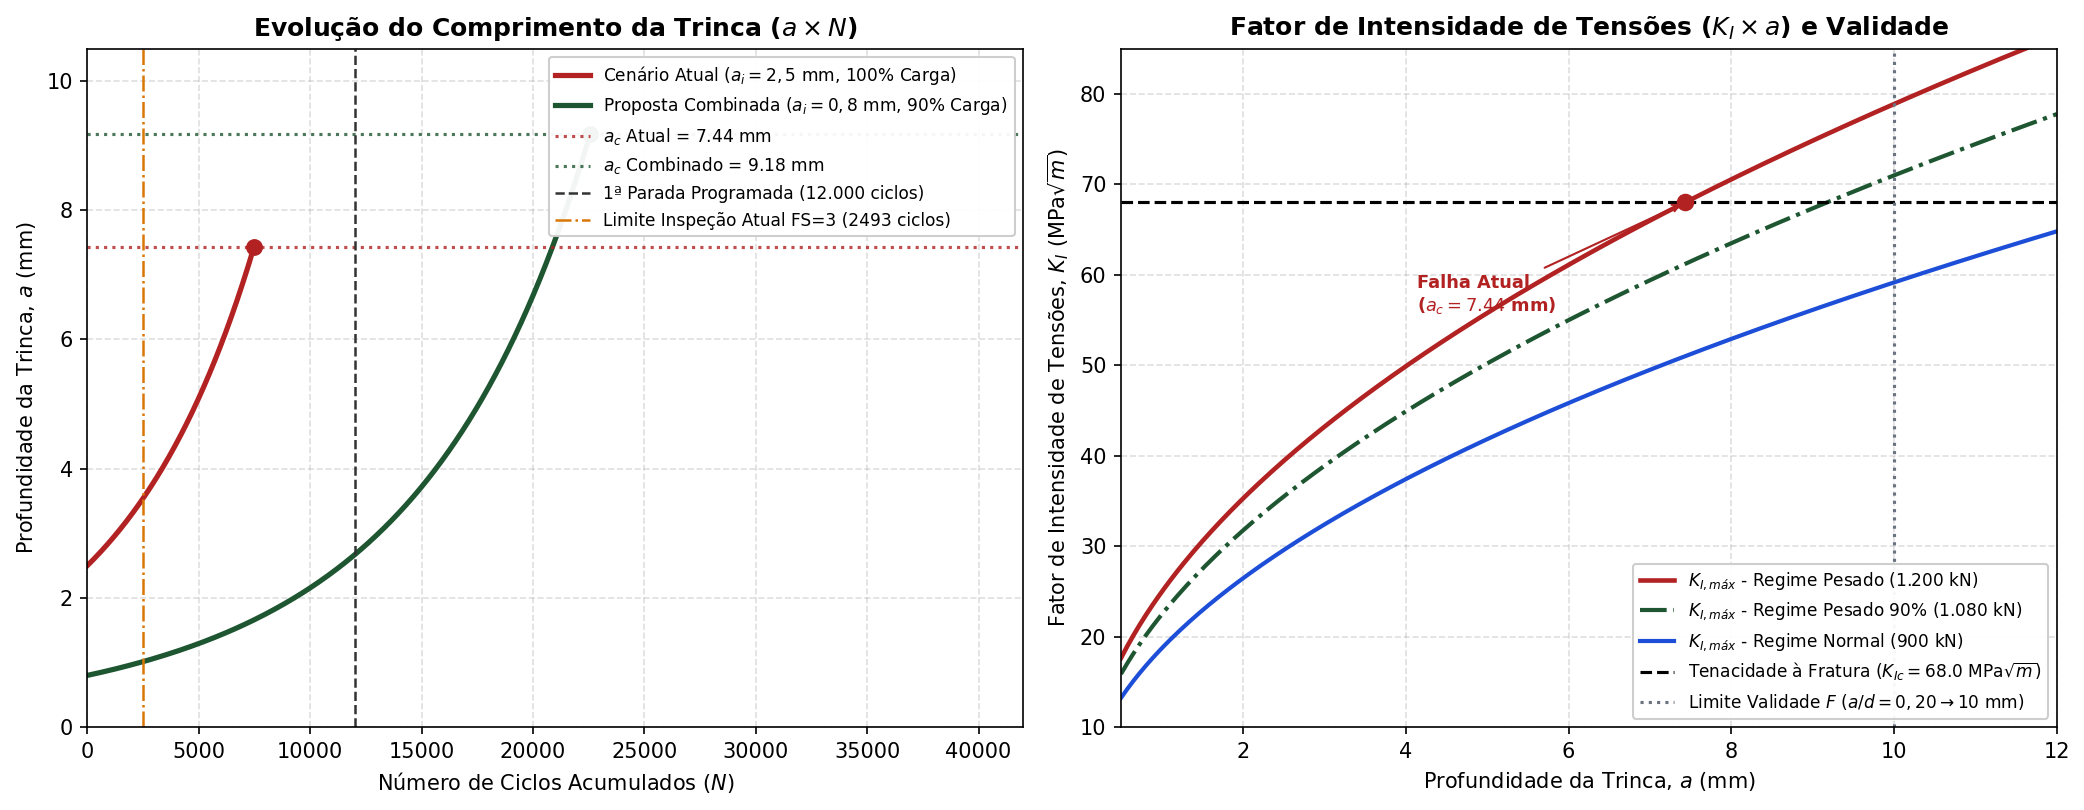

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# 1. DADOS DE PROJETO, GEOMETRIA E CARREGAMENTO (Tabela 1 do Memorial)
# ==============================================================================
n_colunas = 4
d = 50.0e-3               # Diâmetro nominal da coluna (m) -> 50 mm
L = 400.0e-3              # Comprimento livre de referência (m) -> 400 mm
A_0 = (np.pi * d**2) / 4  # Área bruta da seção transversal (m²)

# Propriedades do Material (Aço AISI 4340 Martensítico Revenido)
sigma_y = 1620.0          # Limite de escoamento (MPa)
K_Ic = 68.0               # Tenacidade à fratura (MPa * m^0.5)

# Parâmetros de Propagação (Lei de Paris, R = 0)
C_mm = 1.36e-7            # (mm/ciclo) / (MPa * m^0.5)^m
C_m = C_mm * 1e-3         # Convertido para (m/ciclo) / (MPa * m^0.5)^m
m = 2.25                  # Expoente de Paris

# Defeito Inicial e Fator Geométrico (Dowling Fig. 8.17, caso d)
a_i = 2.5e-3              # Profundidade inicial de referência (m) -> 2.5 mm
F = 0.728                 # Fator geométrico (válido para a/d < 0.20)

# Carregamentos (R = 0 -> P_min = 0 -> Delta_S = S_t_max)
P_normal = 900.0e3        # Força por coluna no regime normal (N)
P_pesado = 1200.0e3       # Força por coluna no regime pesado (N)
f_1 = 0.75                # Fração de ciclos - Regime Normal
f_2 = 0.25                # Fração de ciclos - Regime Pesado

# Planejamento Operacional e Critério de Segurança
N_total_planejado = 48000 # 12.000 ciclos/ano por 4 anos
ciclos_por_ano = 12000
FS = 3.0                  # Fator de segurança determinístico

# Cálculo das Tensões Nominais de Tração (Eq. 2, 3 e 4)
S_t1 = (4 * P_normal) / (np.pi * d**2) * 1e-6  # MPa
S_t2 = (4 * P_pesado) / (np.pi * d**2) * 1e-6  # MPa

# ==============================================================================
# 2. ITEM (a): COMPRIMENTO FINAL CRÍTICO E MODO PREFERENCIAL DE FALHA
# ==============================================================================
# Critério 1: Fratura Frágil Instável sob carga máxima (Eq. 6 e 7)
a_cK = (1 / np.pi) * (K_Ic / (F * S_t2))**2    # em metros
razao_ad = a_cK / d                            # Verificação a/d < 0.20

# Critério 2: Falha Dúctil por Colapso Plástico da Seção Líquida (Eq. 8 a 10)
A_trinca_crit = A_0 - (P_pesado / (sigma_y * 1e6))
a_c_plast = np.sqrt((2 * A_trinca_crit) / np.pi) # em metros

a_c = min(a_cK, a_c_plast)
modo_falha = "Falha Frágil (Fratura Instável)" if a_cK < a_c_plast else "Falha Dúctil (Colapso Plástico)"

# ==============================================================================
# 3. ITEM (b): NÚMERO DE CICLOS ATÉ A FALHA (Nf)
# ==============================================================================
# Tensão Equivalente de Bloco Espectral (Eq. 14 e 15)
Delta_S_eq = (f_1 * (S_t1**m) + f_2 * (S_t2**m))**(1 / m)

# Constante agrupada B (Eq. 17)
B = C_m * (F * Delta_S_eq * np.sqrt(np.pi))**m

# Integração Analítica da Lei de Paris (Eq. 18 e 19)
expoente_int = 1 - (m / 2) # -0.125
N_f_analitico = (1 / (B * abs(expoente_int))) * (a_i**(expoente_int) - a_c**(expoente_int))

# ==============================================================================
# 4. ITEM (c): INTERVALO E NÚMERO DE INSPEÇÕES PERIÓDICAS
# ==============================================================================
Delta_N_insp = N_f_analitico / FS
n_intervalos = np.ceil(N_total_planejado / Delta_N_insp)
n_inspecoes_periodicas = int(n_intervalos - 1)

# ==============================================================================
# 5. ITEM (d): LIMITE DE DETECÇÃO INICIAL (ad) PARA ELIMINAR INSPEÇÕES
# ==============================================================================
N_f_req = FS * N_total_planejado
termo_ad = (N_f_req * B * abs(expoente_int)) + (a_c**(expoente_int))
a_d_req = termo_ad**(1 / expoente_int) # em metros

# ==============================================================================
# 6. AVALIAÇÃO DAS ALTERNATIVAS DE INTERVENÇÃO (ITEM 7 DO PROJETO)
# ==============================================================================
def avaliar_cenario(nome, fator_carga, a_inicial_mm):
    a_ini_m = a_inicial_mm * 1e-3
    S2_novo = S_t2 * fator_carga
    Seq_novo = Delta_S_eq * fator_carga
    ac_novo = (1 / np.pi) * (K_Ic / (F * S2_novo))**2
    B_novo = C_m * (F * Seq_novo * np.sqrt(np.pi))**m
    Nf_novo = (1 / (B_novo * abs(expoente_int))) * (a_ini_m**(expoente_int) - ac_novo**(expoente_int))
    dN_insp = Nf_novo / FS
    n_insp_tot = max(0, int(np.ceil(N_total_planejado / dN_insp)) - 1)
    extras = max(0, n_insp_tot - 4)
    return {
        "Cenário": nome,
        "a_i (mm)": a_inicial_mm,
        "a_c (mm)": round(ac_novo * 1e3, 2),
        "N_f (ciclos)": int(round(Nf_novo)),
        "Intervalo FS=3": int(round(dN_insp)),
        "Inspeções Extras": extras
    }

cenarios = [
    avaliar_cenario("Cenário Base (100% Carga, END atual)", 1.00, 2.5),
    avaliar_cenario("(i-A) Redução de 10% na Carga", 0.90, 2.5),
    avaliar_cenario("(i-B) Redução de 20% na Carga", 0.80, 2.5),
    avaliar_cenario("(ii) Melhoria END (a_i = 0,8 mm)", 1.00, 0.8),
    avaliar_cenario("Proposta Combinada (90% Carga + a_i = 0,8 mm)", 0.90, 0.8)
]
df_cenarios = pd.DataFrame(cenarios)

# ==============================================================================
# EXIBIÇÃO DOS RESULTADOS CONSOLIDADOS
# ==============================================================================
print("="*75)
print("CONFERÊNCIA NUMÉRICA: PYTHON vs. MEMORIAL ANALÍTICO")
print("="*75)
print(f"Área bruta (A_0):           {A_0*1e6:.2f} mm² (Memorial: 1963.50 mm²)")
print(f"Tensão Normal (S_t1):       {S_t1:.2f} MPa (Memorial: 458.37 MPa)")
print(f"Tensão Pesada (S_t2):       {S_t2:.2f} MPa (Memorial: 611.15 MPa)")
print(f"Tensão Equivalente (dSeq):  {Delta_S_eq:.2f} MPa (Memorial: 502.15 MPa)")
print("-"*75)
print(f"[Item a] a_c Frágil (K_Ic): {a_cK*1e3:.2f} mm (Memorial: 7.44 mm)")
print(f"[Item a] Razão a_c/d:       {razao_ad:.3f} (< 0.20 -> Válido!)")
print(f"[Item a] a_c Plástico:      {a_c_plast*1e3:.2f} mm (Memorial: 27.90 mm)")
print(f"[Item a] Modo Governante:   {modo_falha}")
print("-"*75)
print(f"[Item b] Constante B:       {B:.4e} (Memorial: 2.899e-04)")
print(f"[Item b] Vida N_f:          {N_f_analitico:.0f} ciclos (Memorial: 7390 ciclos)")
print("-"*75)
print(f"[Item c] Intervalo FS=3:    {Delta_N_insp:.0f} ciclos (Memorial: 2463 ciclos)")
print(f"[Item c] Inspeções Periód.: {n_inspecoes_periodicas} inspeções (Memorial: 19 inspeções)")
print("-"*75)
print(f"[Item d] Novo a_d req.:     {a_d_req*1e6:.3f} µm (Memorial: 0.161 µm)")
print("="*75)
print("\nMATRIZ COMPARATIVA DE ALTERNATIVAS (ITEM 7):")
print(df_cenarios.to_string(index=False))

# ==============================================================================
# 7. GERAÇÃO DOS GRÁFICOS REQUISITADOS NO PROJETO
# ==============================================================================
a_vec = np.linspace(a_i, a_c, 500)
N_vec = (1 / (B * abs(expoente_int))) * (a_i**(expoente_int) - a_vec**(expoente_int))

a_c_comb = (1 / np.pi) * (K_Ic / (F * (S_t2 * 0.90)))**2
B_comb = C_m * (F * (Delta_S_eq * 0.90) * np.sqrt(np.pi))**m
a_vec_comb = np.linspace(0.8e-3, a_c_comb, 500)
N_vec_comb = (1 / (B_comb * abs(expoente_int))) * ((0.8e-3)**(expoente_int) - a_vec_comb**(expoente_int))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)

# --- GRÁFICO 1: Evolução da Trinca (a vs N) ---
ax1 = axes[0]
ax1.plot(N_vec, a_vec * 1e3, color='#B22222', linewidth=2.5, label='Cenário Atual ($a_i = 2,5$ mm, 100% Carga)')
ax1.plot(N_vec_comb, a_vec_comb * 1e3, color='#1E5631', linewidth=2.5, label='Proposta Combinada ($a_i = 0,8$ mm, 90% Carga)')

ax1.axhline(a_c * 1e3, color='#B22222', linestyle=':', alpha=0.8, label=f'$a_c$ Atual = {a_c*1e3:.2f} mm')
ax1.axhline(a_c_comb * 1e3, color='#1E5631', linestyle=':', alpha=0.8, label=f'$a_c$ Combinado = {a_c_comb*1e3:.2f} mm')
ax1.axvline(12000, color='#333333', linestyle='--', linewidth=1.2, label='1ª Parada Programada (12.000 ciclos)')
ax1.axvline(Delta_N_insp, color='#D97706', linestyle='-.', linewidth=1.2, label=f'Limite Inspeção Atual FS=3 ({int(Delta_N_insp)} ciclos)')

ax1.scatter([N_f_analitico], [a_c * 1e3], color='#B22222', zorder=5, s=50)
ax1.scatter([N_vec_comb[-1]], [a_c_comb * 1e3], color='#1E5631', zorder=5, s=50)

ax1.set_title('Evolução do Comprimento da Trinca ($a \\times N$)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Número de Ciclos Acumulados ($N$)', fontsize=10)
ax1.set_ylabel('Profundidade da Trinca, $a$ (mm)', fontsize=10)
ax1.set_xlim(0, 42000)
ax1.set_ylim(0, 10.5)
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend(loc='upper right', fontsize=8.2, framealpha=0.95)

# --- GRÁFICO 2: Fator de Intensidade de Tensões (K_I vs a) e Validade ---
ax2 = axes[1]
a_range = np.linspace(0.5e-3, 12.0e-3, 300)
K_pesado = F * S_t2 * np.sqrt(np.pi * a_range)
K_normal = F * S_t1 * np.sqrt(np.pi * a_range)
K_pesado_90 = F * (S_t2 * 0.90) * np.sqrt(np.pi * a_range)

ax2.plot(a_range * 1e3, K_pesado, color='#B22222', linewidth=2.2, label='$K_{I,máx}$ - Regime Pesado (1.200 kN)')
ax2.plot(a_range * 1e3, K_pesado_90, color='#1E5631', linewidth=2.0, linestyle='-.', label='$K_{I,máx}$ - Regime Pesado 90% (1.080 kN)')
ax2.plot(a_range * 1e3, K_normal, color='#1D4ED8', linewidth=2.0, label='$K_{I,máx}$ - Regime Normal (900 kN)')

ax2.axhline(K_Ic, color='black', linestyle='--', linewidth=1.5, label=f'Tenacidade à Fratura ($K_{{Ic}} = {K_Ic}$ MPa$\\sqrt{{m}}$)')
ax2.axvline(0.20 * d * 1e3, color='#6B7280', linestyle=':', linewidth=1.5, label='Limite Validade $F$ ($a/d = 0,20 \\rightarrow 10$ mm)')

ax2.scatter([a_c * 1e3], [K_Ic], color='#B22222', zorder=5, s=55)
ax2.annotate(f'Falha Atual\n($a_c = {a_c*1e3:.2f}$ mm)', xy=(a_c*1e3, K_Ic), xytext=(a_c*1e3 - 3.3, K_Ic - 12),
             arrowprops=dict(arrowstyle='->', color='#B22222'), fontsize=8.5, fontweight='bold', color='#B22222')

ax2.set_title('Fator de Intensidade de Tensões ($K_I \\times a$) e Validade', fontsize=12, fontweight='bold')
ax2.set_xlabel('Profundidade da Trinca, $a$ (mm)', fontsize=10)
ax2.set_ylabel('Fator de Intensidade de Tensões, $K_I$ (MPa$\\sqrt{m}$)', fontsize=10)
ax2.set_xlim(0.5, 12.0)
ax2.set_ylim(10, 85)
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend(loc='lower right', fontsize=8.2, framealpha=0.95)

plt.tight_layout()
plt.savefig('graficos_integridade_prensa.png', dpi=300)
plt.show()

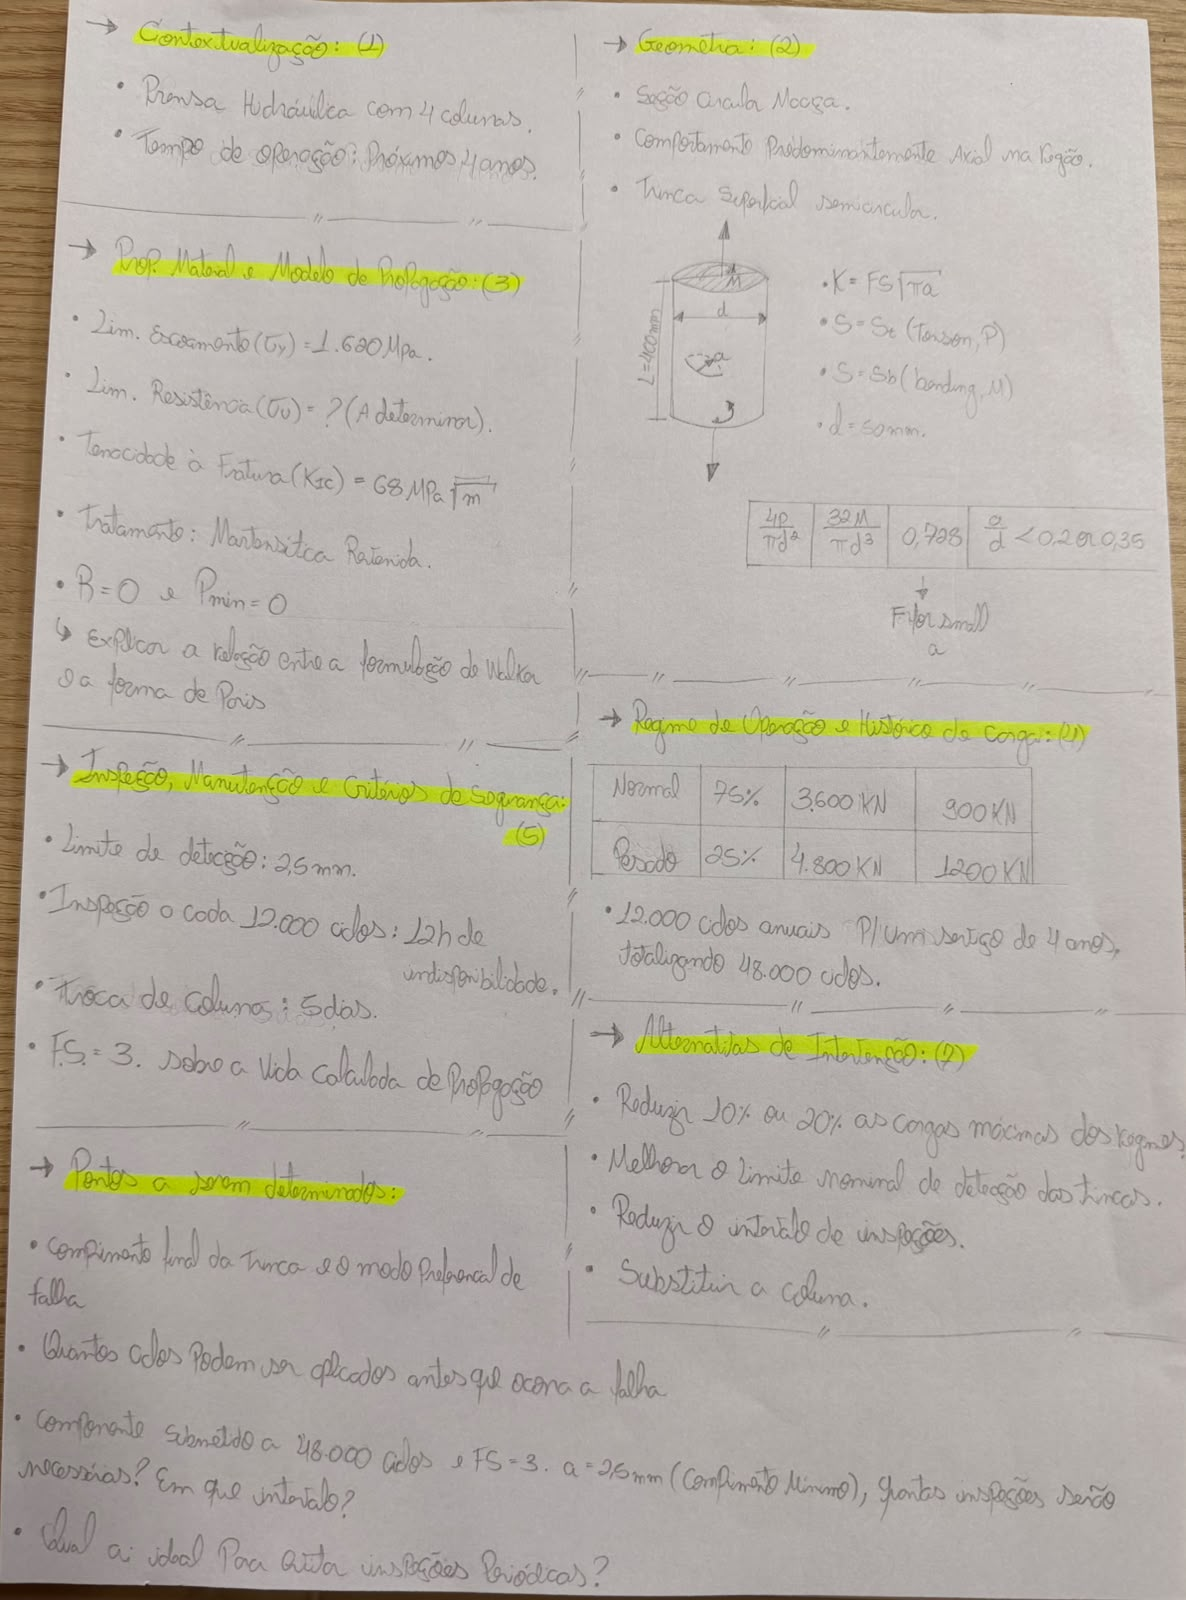

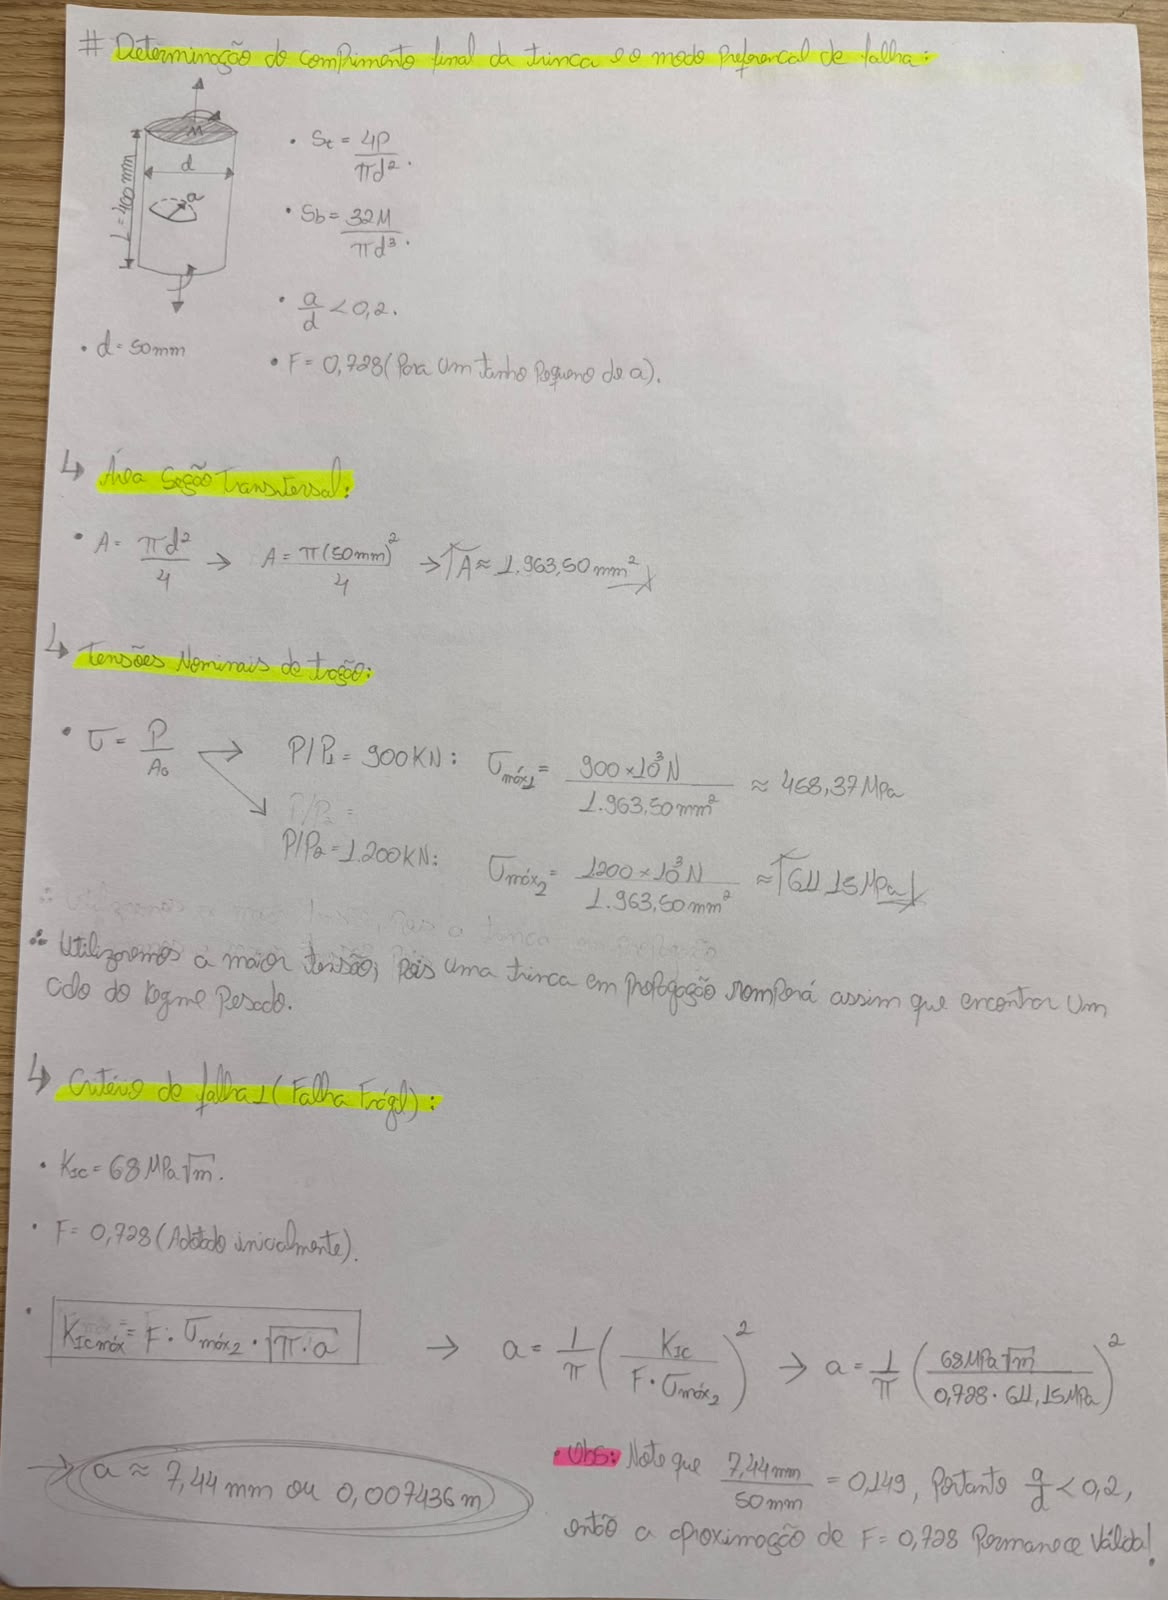

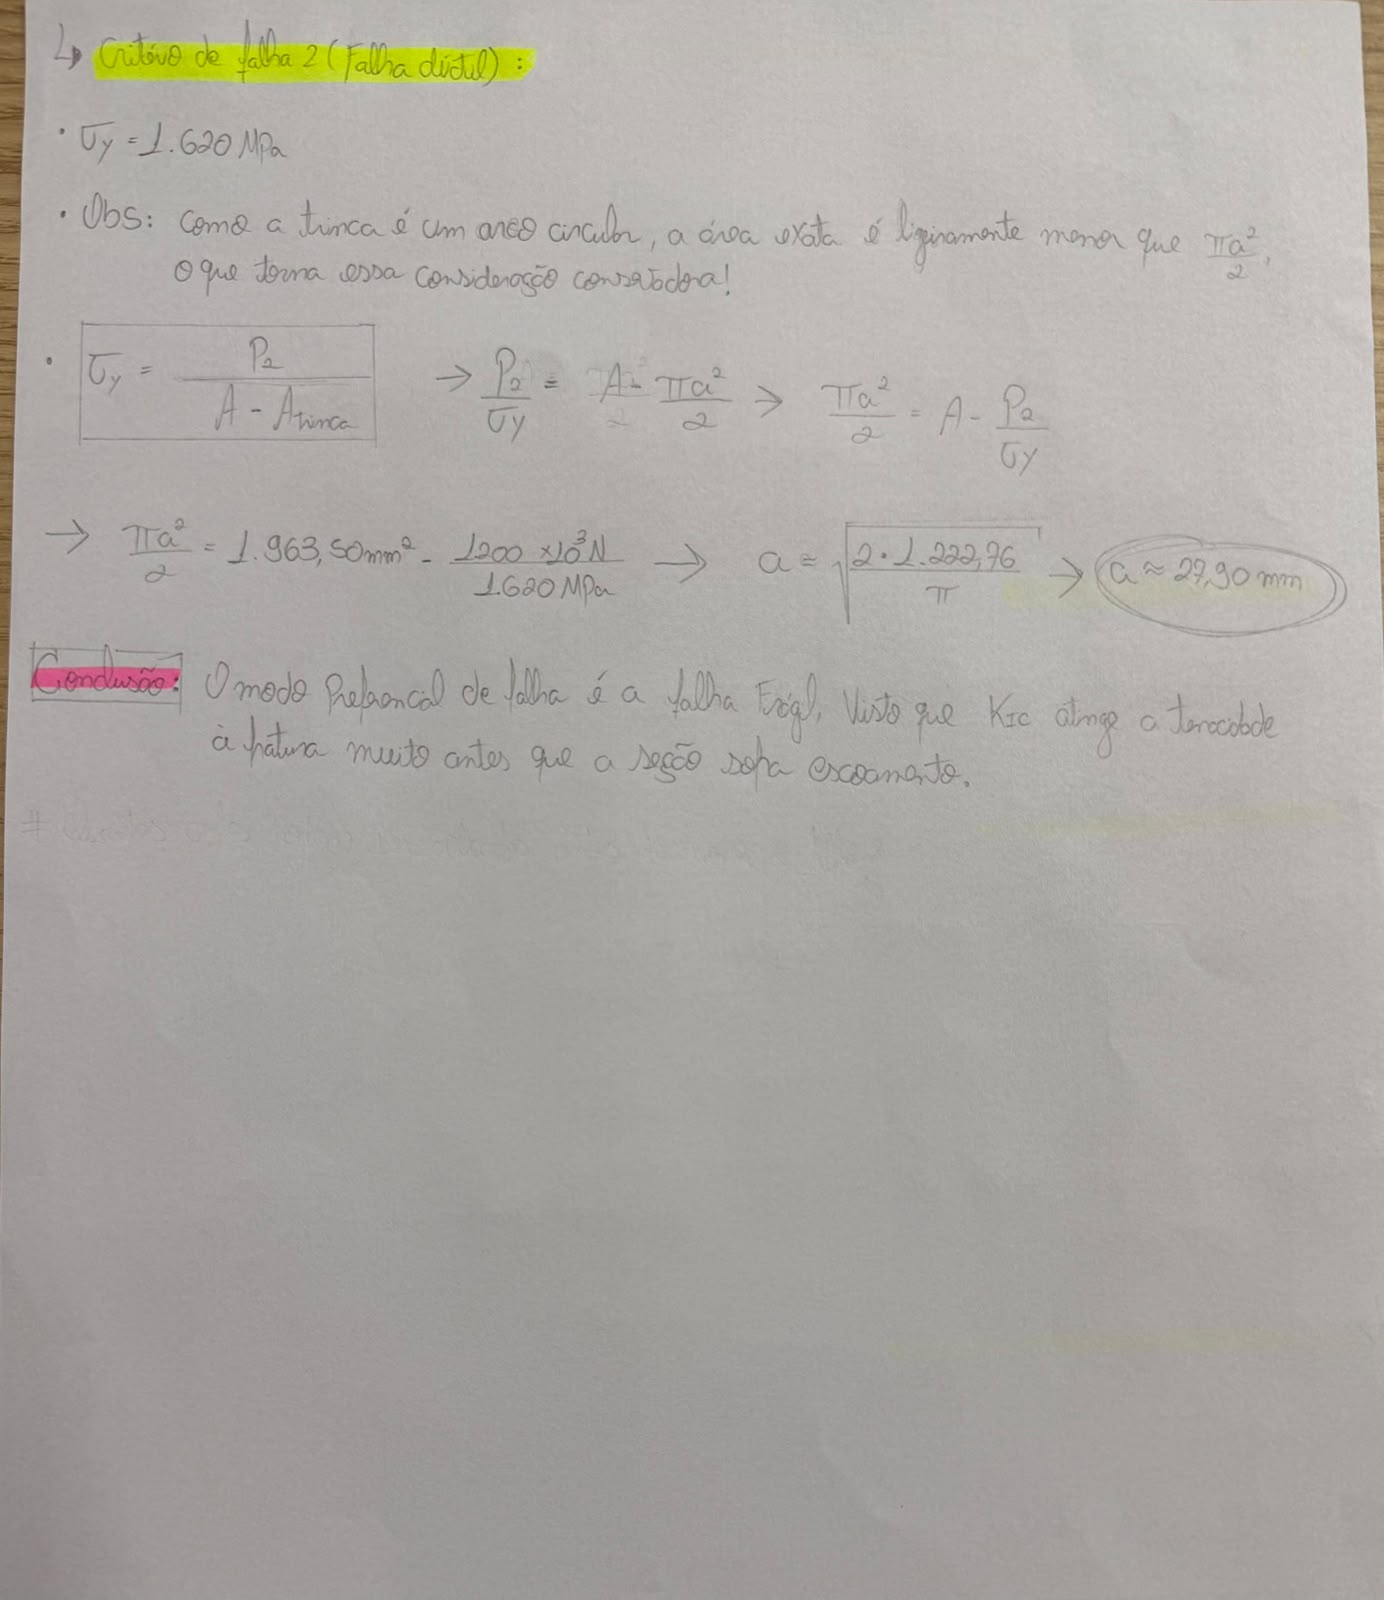